# B4 — Gán nhãn giả (Pseudo-Labeling), Ensemble Voting & Gộp Dữ liệu Vòng 1

**Mục tiêu của Bước 4 (B4):**
1. **True Unsupervised Pseudo-Labeling:** Dùng các mô hình đã huấn luyện ở Run 1 (`B3`) suy luận xác suất đầy đủ 4 lớp trên `unlabeled_clean.csv` (`54.487` mẫu không nhãn sạch, không rò rỉ với Train/Test).
2. **Ensemble Consensus Voting Vòng 1:** Kết hợp các mô hình bằng bộ lọc đồng thuận kép:
   - Số phiếu đồng thuận cứng `vote_count >= ceil(N_models × 0.60)` (tối thiểu **5/7** mô hình).
   - Nhãn bỏ phiếu mềm có trọng số (`Val Macro-F1`) TRÙNG với nhãn bỏ phiếu cứng.
   - Độ tin cậy `confidence >= 0.94` và biên độ `margin = p(1) - p(2) >= 0.50`.
3. **Selective Class-Balanced Combining:** Gộp `train_pool.csv` (`24.628` mẫu) với các mẫu nhãn giả có độ tin cậy cao nhất từng lớp để kéo 4 lớp về cân bằng quanh mục tiêu `9.500` mẫu/lớp (khắc phục trực tiếp *Prior Shift* `+11.31%` của lớp *Environment*) → xuất `combined_round1.csv`.
4. **Biểu đồ xuất tại `workspace_outputs/figures/B4_pseudo_round1/` (300 DPI `.png` + `.pdf`):**
   - `B4_01_phan_bo_confidence_vong1`: Phân bố độ tin cậy (KDE & % vượt ngưỡng) của từng mô hình.
   - `B4_02_ma_tran_dong_thuan_kappa`: Ma trận đồng thuận (%) & Hệ số Cohen's Kappa giữa các cặp mô hình.
   - `B4_03_phan_bo_so_phieu_bau`: Phân bố số phiếu đồng thuận (`1/N → N/N`).
   - `B4_04_can_bang_lop_sau_vong1`: Biểu đồ cột chồng Trước & Sau Combine Vòng 1.

In [17]:
# Bước 4.1: Khởi tạo cấu hình & công tắc tinh chỉnh ngưỡng cho Vòng 1
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    CHECKPOINTS_DIR,
    PSEUDO_ROUND1_DIR,
    METRICS_DIR,
    LABEL_NAMES,
)
from src.pseudo_labeler import UnsupervisedPseudoLabeler
from src.ensemble import EnsembleVoter
from src.combiner import SelectiveDataCombiner
from src.viz_utils import (
    plot_pseudo_confidence_distribution,
    plot_pairwise_agreement_heatmap,
    plot_vote_count_distribution,
    plot_before_after_combine_distribution,
)

ensure_directories()

# ==================== CÔNG TẮC LINH HOẠT CHO BƯỚC B4 ====================
cfg = PipelineConfig(
    hardware_mode="balanced",
    model_preset="full_7",                # Phải khớp với các mô hình đã train ở Bước B3
    skip_if_done=True,                    # True -> không chạy lại inference cho model đã có .parquet
    round1_confidence_threshold=0.94,
    round1_min_margin=0.50,
    round1_min_vote_ratio=0.60,           # >= 5/7 mô hình đồng thuận (hoặc >= 2/3 với fast_3)
    round1_target_per_class=9_500,
    use_weighted_voting=True,
)
# Nếu muốn tự nhập tay số lượng gộp cho từng lớp (thay vì gợi ý tự động), gán dict vd: {0: 4000, 1: 5000, 2: 500, 3: 3000}
CUSTOM_ADD_COUNTS = None
# ========================================================================

set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B4")

print(cfg.summary())
print(f"\nNơi lưu kết quả Pseudo Vòng 1: {PSEUDO_ROUND1_DIR}")
print(f"Nơi lưu biểu đồ Bước B4      : {FIG_DIR}")

=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Ablation Baseline: bật=True | gói=fast_3 (electra-base-vn, phobert-base, visobert)
- Công tắc an toàn : skip_if_done=True | seed=42
- Siêu tham số     : max_length=256 | lr=2e-05 | warmup=0.1 | metric=f1_macro
- Pseudo & Cân bằng: R1(conf>=0.94, margin>=0.5, target=9,500/lớp) | R2(conf>=0.91, target=10,500/lớp)
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu kết quả Pseudo Vòng 1: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\pseudo_round1
Nơi lưu biểu đồ Bước B4      : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_ou

In [18]:
# Bước 4.2: Đọc dữ liệu không nhãn sạch & tự động nạp trọng số Val Macro-F1 từ Bước B3
unlabeled_df = pd.read_csv(PROCESSED_DATA_DIR / "unlabeled_clean.csv")
train_pool_df = pd.read_csv(PROCESSED_DATA_DIR / "train_pool.csv")

print(f"- unlabeled_clean.csv : {len(unlabeled_df):,} mẫu không nhãn")
print(f"- train_pool.csv      : {len(train_pool_df):,} mẫu gốc")

# Kiểm tra các checkpoint Run 1 sẵn sàng & đọc trọng số Val Macro-F1 từ train_summary.json
ready_models = []
model_weights = {}
for spec in cfg.get_active_models():
    ckpt_dir = CHECKPOINTS_DIR / "run1" / spec.short_name
    summary_path = METRICS_DIR / f"run1_{spec.short_name}_train_summary.json"
    if (ckpt_dir / "model_metadata.json").exists():
        ready_models.append(spec)
        if summary_path.exists():
            with open(summary_path, "r", encoding="utf-8") as f:
                s = json.load(f)
            model_weights[spec.display_name] = float(s.get("best_val_metrics", {}).get("eval_f1_macro", 1.0))
        else:
            model_weights[spec.display_name] = 1.0
    else:
        print(f"[Cảnh báo] Chưa tìm thấy checkpoint Run 1 cho {spec.display_name} tại {ckpt_dir} -> bỏ qua.")

print(f"\nSố mô hình Run 1 sẵn sàng suy luận: {len(ready_models)} -> {[m.display_name for m in ready_models]}")
print(f"Trọng số bỏ phiếu (Val Macro-F1)  : { {k: round(v, 4) for k, v in model_weights.items()} }")
assert len(ready_models) >= 2, "Cần ít nhất 2 mô hình Run 1 đã huấn luyện ở Bước B3 trước khi chạy Bước B4!"

- unlabeled_clean.csv : 54,487 mẫu không nhãn
- train_pool.csv      : 24,628 mẫu gốc

Số mô hình Run 1 sẵn sàng suy luận: 7 -> ['PhoBERT-base', 'DistilBERT-m', 'mBERT-cased', 'RoBERTa-base', 'Vi-ELECTRA', 'ViSoBERT', 'ViDeBERTa-base']
Trọng số bỏ phiếu (Val Macro-F1)  : {'PhoBERT-base': 0.8957, 'DistilBERT-m': 0.8611, 'mBERT-cased': 0.881, 'RoBERTa-base': 0.8095, 'Vi-ELECTRA': 0.8803, 'ViSoBERT': 0.8454, 'ViDeBERTa-base': 0.1341}


In [19]:
# Bước 4.3: Suy luận xác suất 4 lớp của từng mô hình Run 1 trên 54.487 câu không nhãn (BF16)
labeler = UnsupervisedPseudoLabeler(cfg)
per_model_files = {}
per_model_confs = {}

for spec in ready_models:
    ckpt_dir = CHECKPOINTS_DIR / "run1" / spec.short_name
    out_parquet = PSEUDO_ROUND1_DIR / "per_model" / f"{spec.short_name}_r1.parquet"

    pred_df = labeler.predict_unlabeled(
        model_spec=spec,
        checkpoint_dir=ckpt_dir,
        unlabeled_df=unlabeled_df,
        output_path=out_parquet,
        round_tag="r1",
    )
    per_model_files[spec.display_name] = out_parquet
    per_model_confs[spec.display_name] = pred_df["confidence"].to_numpy(dtype=np.float32)

print("\n[HOÀN TẤT] Đã sinh đủ tệp xác suất .parquet cho tất cả mô hình Run 1!")

[Bỏ qua Pseudo] [r1] PhoBERT-base đã có tệp phobert-base_r1.parquet -> nạp lại.
[Bỏ qua Pseudo] [r1] DistilBERT-m đã có tệp distilbert-base-multilingual-cased_r1.parquet -> nạp lại.
[Bỏ qua Pseudo] [r1] mBERT-cased đã có tệp bert-base-multilingual-cased_r1.parquet -> nạp lại.
[Bỏ qua Pseudo] [r1] RoBERTa-base đã có tệp roberta-base_r1.parquet -> nạp lại.
[Bỏ qua Pseudo] [r1] Vi-ELECTRA đã có tệp electra-base-vn_r1.parquet -> nạp lại.
[Bỏ qua Pseudo] [r1] ViSoBERT đã có tệp visobert_r1.parquet -> nạp lại.

[Pseudo-Labeling r1] Mô hình: ViDeBERTa-base | Số câu: 54,487 | pyvi=False
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run1\videberta-base


Pseudo [r1] ViDeBERTa-base: 100%|██████████| 852/852 [00:41<00:00, 20.73batch/s]


  => Xong ViDeBERTa-base: 0/54,487 mẫu đạt conf >= 0.94 (0.0%) | Tốc độ=1323.5 mẫu/s (41.2s)

[HOÀN TẤT] Đã sinh đủ tệp xác suất .parquet cho tất cả mô hình Run 1!


In [20]:
# Bước 4.4: Chạy Ensemble Consensus Voting Vòng 1 -> ensemble_pseudo_r1.csv & remain_data_r1.csv
voter = EnsembleVoter(
    confidence_threshold=cfg.round1_confidence_threshold,
    min_vote_ratio=cfg.round1_min_vote_ratio,
    min_margin=cfg.round1_min_margin,
    model_weights=model_weights,
    use_weighted_voting=cfg.use_weighted_voting,
)

ensemble_pseudo_r1, remain_data_r1, ensemble_report_r1 = voter.vote_pseudo_labels(
    per_model_files=per_model_files,
    unlabeled_df=unlabeled_df,
    output_dir=PSEUDO_ROUND1_DIR,
    round_tag="r1",
    text_col=cfg.text_column,
)

display(ensemble_pseudo_r1[["text_id", "vi_text", "label_name", "confidence", "margin", "vote_count"]].head(5))


[ENSEMBLE VOTING R1] Hoàn tất bỏ phiếu 7 mô hình!
  - Điều kiện lọc : vote >= 5/7 | conf >= 0.94 | margin >= 0.5 | Hard == Soft
  - Kết quả       : Giữ 23,378/54,487 mẫu (42.91%) | Còn dư 31,109 mẫu
  - Chất lượng    : Avg Conf=0.9682 | Avg Margin=0.9533 | Mean Kappa=0.5004
  - Phân bố nhãn  : {'Irrelevant': 592, 'Environment': 7287, 'Social': 7812, 'Governance': 7687}


,text_id,vi_text,label_name,confidence,margin,vote_count
0,unl_008277,giáo dục người dùng và khách hàng chất lượng c...,Social,0.979051,0.970647,7
1,unl_033689,mental well-being td cung cấp nhiều lựa chọn c...,Social,0.979043,0.970836,7
2,unl_010604,cung cấp lợi ích cho tất cả nhân viên hoa kỳ v...,Social,0.978962,0.970527,7
3,unl_037144,triết lý bồi thường dựa trên việc thưởng cho t...,Social,0.978950,0.970589,7
4,unl_032466,mặc dù mọi người trong các vùng khác nhau phản...,Social,0.978922,0.970312,7


In [21]:
# Bước 4.5: Gộp dữ liệu có chọn lọc & cân bằng lớp (Selective Class-Balanced Combining Vòng 1)
combiner = SelectiveDataCombiner(text_col=cfg.text_column, label_col=cfg.label_column, seed=cfg.seed)

suggested_counts = combiner.suggest_balanced_counts(
    original_df=train_pool_df,
    pseudo_df=ensemble_pseudo_r1,
    target_per_class=cfg.round1_target_per_class,
)

add_counts_r1 = CUSTOM_ADD_COUNTS if CUSTOM_ADD_COUNTS is not None else suggested_counts
print(f"\nSố lượng áp dụng gộp Vòng 1: {add_counts_r1}")

combined_round1_df, remaining_pseudo_r1_df, dist_info_r1 = combiner.combine(
    original_df=train_pool_df,
    pseudo_df=ensemble_pseudo_r1,
    add_counts=add_counts_r1,
    output_dir=PSEUDO_ROUND1_DIR,
    round_name="round1",
)

=== GỢI Ý SỐ LƯỢNG GỘP CÂN BẰNG LỚP ===
Lớp                |  Hiện có | Pseudo có sẵn | Đề xuất thêm | Tổng sau gộp
--------------------------------------------------------------------------
0 - Irrelevant     |    5,312 |           592 |          592 |        5,904
1 - Environment    |    3,945 |         7,287 |        5,555 |        9,500
2 - Social         |    9,023 |         7,812 |          477 |        9,500
3 - Governance     |    6,348 |         7,687 |        3,152 |        9,500

Số lượng áp dụng gộp Vòng 1: {0: 592, 1: 5555, 2: 477, 3: 3152}

=== KẾT QUẢ GỘP DỮ LIỆU (ROUND1) ===
  Lớp 0 (Irrelevant ):  5,312 (trước) +   592 (pseudo) =  5,904 (sau) | Dư pseudo:     0
  Lớp 1 (Environment):  3,945 (trước) + 5,555 (pseudo) =  9,500 (sau) | Dư pseudo: 1,732
  Lớp 2 (Social     ):  9,023 (trước) +   477 (pseudo) =  9,500 (sau) | Dư pseudo: 7,335
  Lớp 3 (Governance ):  6,348 (trước) + 3,152 (pseudo) =  9,500 (sau) | Dư pseudo: 4,535
  => Tổng mẫu: 24,628 -> 34,404 (+9,776 pseudo

[Đã lưu biểu đồ] B4_01_phan_bo_confidence_vong1.png, B4_01_phan_bo_confidence_vong1.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B4_pseudo_round1


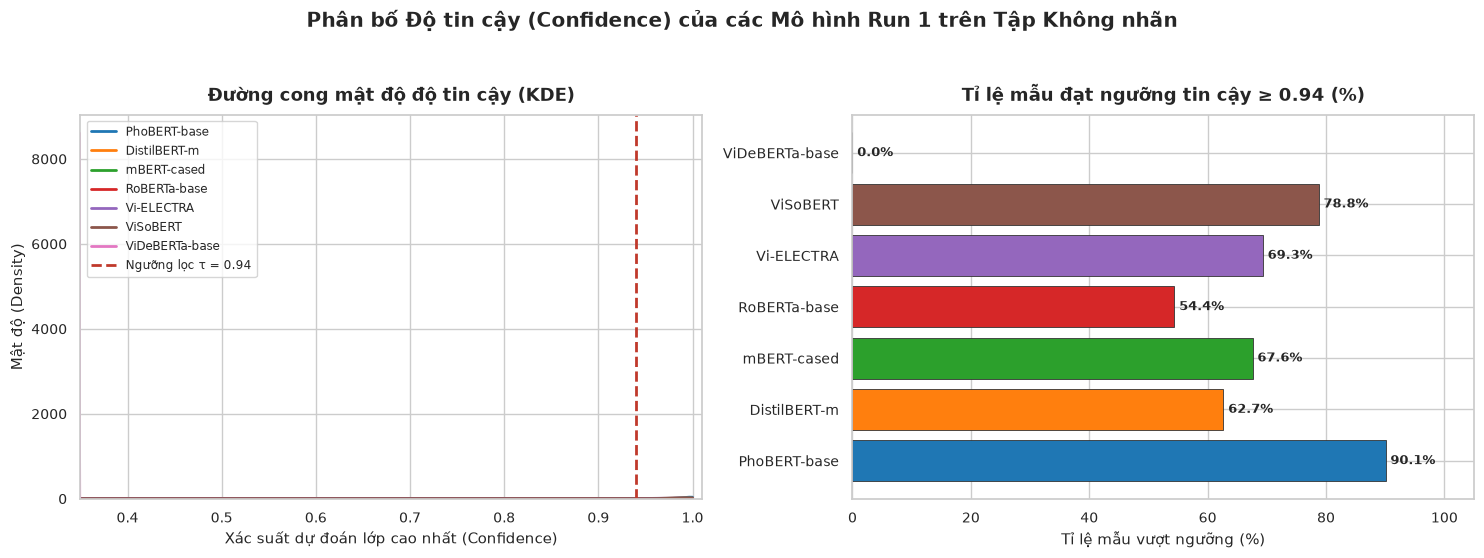

[Đã lưu biểu đồ] B4_02_ma_tran_dong_thuan_kappa.png, B4_02_ma_tran_dong_thuan_kappa.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B4_pseudo_round1


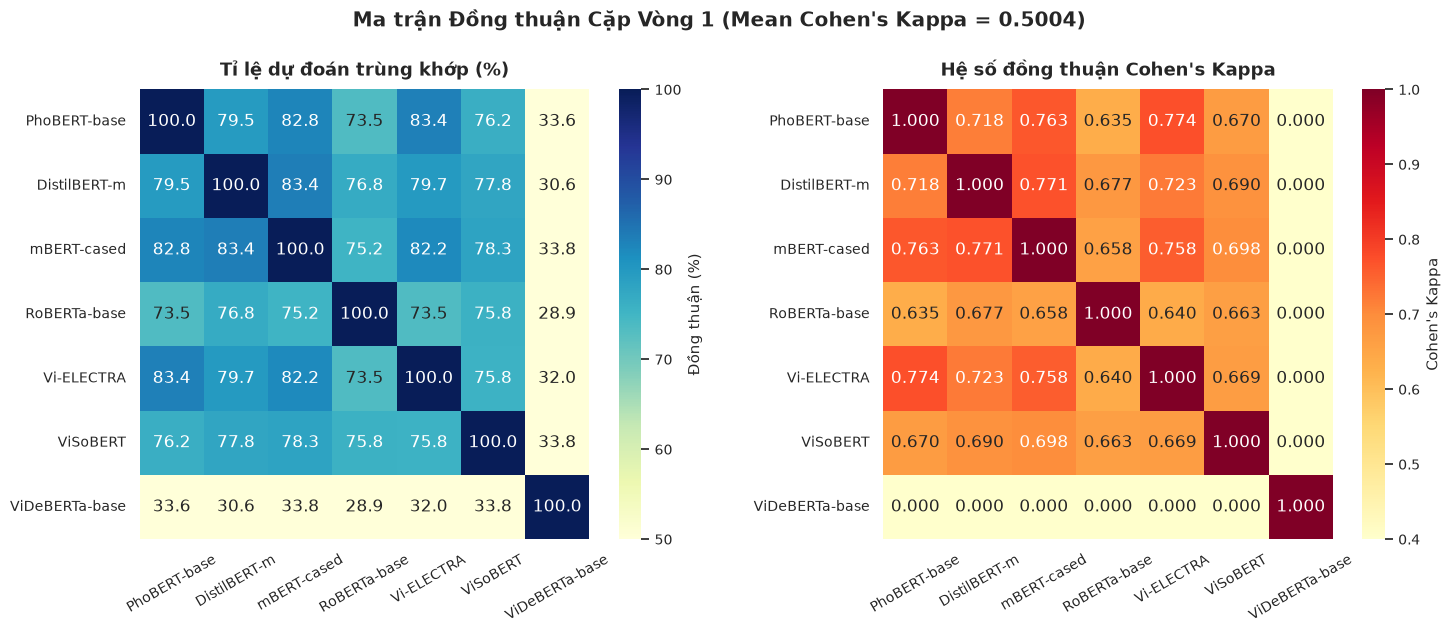

In [22]:
# Bước 4.6 — Biểu đồ B4.1 (Phân bố Confidence) & B4.2 (Ma trận Đồng thuận & Cohen's Kappa)
fig_conf = plot_pseudo_confidence_distribution(
    per_model_confs=per_model_confs,
    threshold=cfg.round1_confidence_threshold,
    title="Phân bố Độ tin cậy (Confidence) của các Mô hình Run 1 trên Tập Không nhãn",
    save_dir=FIG_DIR,
    filename_stem="B4_01_phan_bo_confidence_vong1",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

agree_df = pd.DataFrame(ensemble_report_r1["pairwise_agreement_pct"])
kappa_df = pd.DataFrame(ensemble_report_r1["pairwise_cohen_kappa"])
fig_kappa = plot_pairwise_agreement_heatmap(
    agreement_df=agree_df,
    kappa_df=kappa_df,
    title=f"Ma trận Đồng thuận Cặp Vòng 1 (Mean Cohen's Kappa = {ensemble_report_r1['mean_pairwise_kappa']:.4f})",
    save_dir=FIG_DIR,
    filename_stem="B4_02_ma_tran_dong_thuan_kappa",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B4_03_phan_bo_so_phieu_bau.png, B4_03_phan_bo_so_phieu_bau.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B4_pseudo_round1


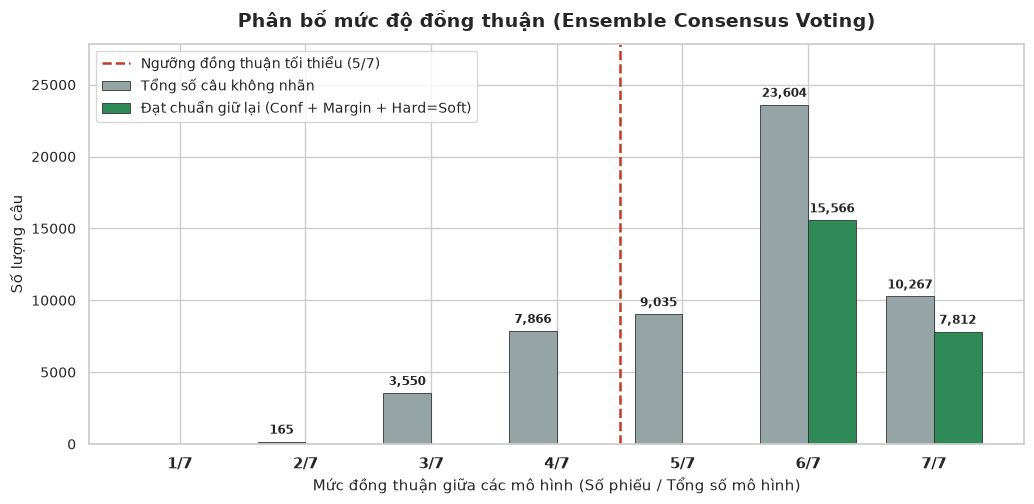

[Đã lưu biểu đồ] B4_04_can_bang_lop_sau_vong1.png, B4_04_can_bang_lop_sau_vong1.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B4_pseudo_round1


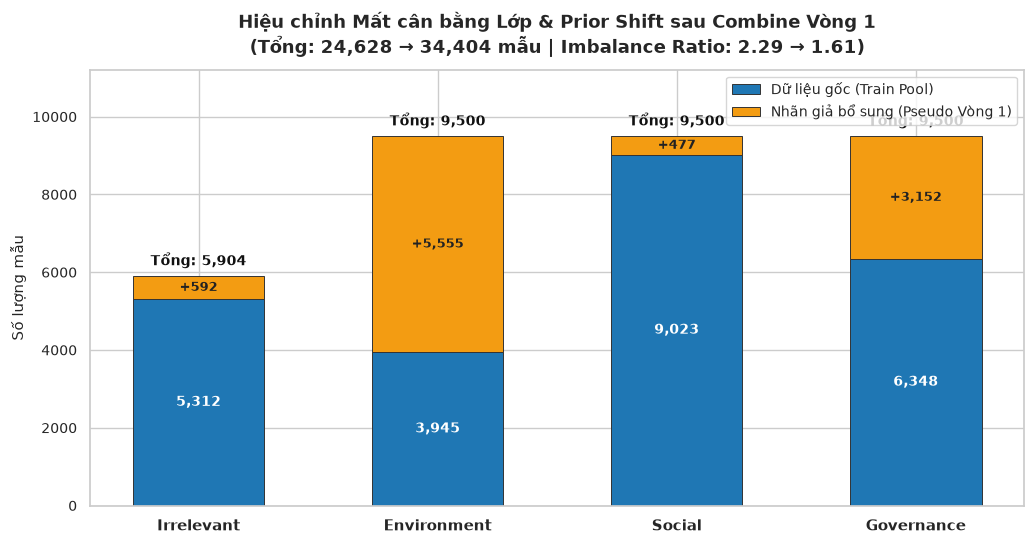

In [23]:
# Bước 4.7 — Biểu đồ B4.3 (Số phiếu đồng thuận) & B4.4 (Cân bằng lớp Trước & Sau Combine Vòng 1)
fig_votes = plot_vote_count_distribution(
    vote_dist_all=ensemble_report_r1["vote_distribution_all"],
    vote_dist_kept=ensemble_report_r1["vote_distribution_kept"],
    min_votes_required=ensemble_report_r1["min_votes_required"],
    total_models=len(ensemble_report_r1["models"]),
    save_dir=FIG_DIR,
    filename_stem="B4_03_phan_bo_so_phieu_bau",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

fig_bal = plot_before_after_combine_distribution(
    distribution_info=dist_info_r1,
    title="Hiệu chỉnh Mất cân bằng Lớp & Prior Shift sau Combine Vòng 1",
    save_dir=FIG_DIR,
    filename_stem="B4_04_can_bang_lop_sau_vong1",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

In [24]:
# Bước 4.8: Kiểm tra định tính (Qualitative Inspection) — Xem câu mẫu tin cậy cao nhất & sát ngưỡng từng lớp
sample_rows = []
for c, name in enumerate(LABEL_NAMES):
    sub = ensemble_pseudo_r1[ensemble_pseudo_r1["labels"] == c]
    if len(sub) == 0:
        continue
    top2 = sub.head(2).assign(nhom="Tin cậy cao nhất")
    border2 = sub.tail(2).assign(nhom="Cận ngưỡng lọc")
    sample_rows.append(pd.concat([top2, border2]))

if sample_rows:
    qual_df = pd.concat(sample_rows, ignore_index=True)[
        ["label_name", "nhom", "confidence", "margin", "vote_count", "vi_text"]
    ]
    qual_df["vi_text"] = qual_df["vi_text"].str.slice(0, 160)
    display(qual_df)

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B4_pseudo_round1 ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")

,label_name,nhom,confidence,margin,vote_count,vi_text
0,Irrelevant,Tin cậy cao nhất,0.969960,0.956743,6,chính sự hiểu biết cơ bản này đánh dấu sự khởi...
1,Irrelevant,Tin cậy cao nhất,0.969923,0.957123,6,"trong suốt gần sáu thập kỷ, chúng tôi luôn tin..."
2,Irrelevant,Cận ngưỡng lọc,0.940238,0.901035,6,ngày mất tích tính từ ngày sau tai nạn.
3,Irrelevant,Cận ngưỡng lọc,0.940186,0.916982,6,"ngày hôm nay, united đang làm nên lịch sử một ..."
4,Environment,Tin cậy cao nhất,0.972973,0.962519,6,"tại úc, theo khí trình báo cáo khí nhà kính và..."
5,Environment,Tin cậy cao nhất,0.972940,0.962405,6,trên euro 6 homologation v-address maserati đã...
6,Environment,Cận ngưỡng lọc,0.940082,0.903319,6,giống như coors đi đầu bằng cách tiên phong sả...
7,Environment,Cận ngưỡng lọc,0.940048,0.903712,6,"tuy nhiên, một số địa điểm ở châu á của chúng ..."
8,Social,Tin cậy cao nhất,0.979051,0.970647,7,giáo dục người dùng và khách hàng chất lượng c...
9,Social,Tin cậy cao nhất,0.979043,0.970836,7,mental well-being td cung cấp nhiều lựa chọn c...



=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B4_pseudo_round1 ===
  - B4_01_phan_bo_confidence_vong1.pdf
  - B4_01_phan_bo_confidence_vong1.png
  - B4_02_ma_tran_dong_thuan_kappa.pdf
  - B4_02_ma_tran_dong_thuan_kappa.png
  - B4_03_phan_bo_so_phieu_bau.pdf
  - B4_03_phan_bo_so_phieu_bau.png
  - B4_04_can_bang_lop_sau_vong1.pdf
  - B4_04_can_bang_lop_sau_vong1.png
